# Ekman transport, MSE and Ekman advection maps

Plots one group (pentad or BSISO phase) of a composite NetCDF file written by `save_composite`. The library `ekman_V_ma_mo_plot.jl` holds the plot defaults, the reader, field computations, `panel` and `plot_panels`; the panels (data, labels, colors, limits) are set here. The library is loaded with Revise `includet`, so edits to it take effect here without restarting the kernel.

Kernel: "Julia", the juliaup default Julia, started with `--project=@.`, which finds `plot/Project.toml`.

In [5]:
using Revise
includet("ekman_V_ma_mo_plot.jl")

## Data
Pentad `p` in the region `lonlim`, `latlim`; only that region is read from the file. `d`: the composite fields as read; `f`: the fields plotted (transport, MSE, gradients, advection, flux terms). Both are NamedTuples; `keys(f)` lists them, e.g. `f.adv_o`. Gradients are NaN on the region's edge rows and columns.

The composites use the uncurtailed Ekman transport. `ekman_fields` multiplies M by `r = curtail(lat, Ro_rad)` (`f.r`), a function of latitude only, so `Ro_rad` can be changed here without recompositing. It matters only within ~5° of the equator.

In [6]:
using Dates
file = "../ekman_pentad_clim_2012-2020.nc"
p = 30                            # pentad (days 5p-4 to 5p of the 365-day year)
lonlim, latlim = (40, 110), (-5, 30) # degrees: Indian Ocean; only this region is read
Ro_rad = 250e3 # m, curtail M by r = 1 - exp(-y^2/Ro_rad^2) near the equator (plotting only)
k = findfirst(==(p), NCDataset(nc -> nc["pentad"][:], file)) # index of pentad p in the file
d = read_group(file, k; lonlim, latlim)
f = ekman_fields(d; Ro_rad)
first_day = Date(2001, 1, 1) + Day(5p - 5) # pentad p on the 365-day calendar (2001: not a leap year)
last_day = first_day + Day(4)
dates = Dates.format(first_day, "u d") * "-" * Dates.format(last_day, month(last_day) == month(first_day) ? "d" : "u d")
figtitle = "$(basename(file)): $dates (Ro_rad = $(Ro_rad/1e3) km)"
size(f.Mx), keys(f)

((281, 141), (:lon, :lat, :Mx, :My, :m_a, :m_o, :dmodx, :dmody, :dmadx, :dmady, :advT_o, :advT_a, :adv_o, :adv_a, :sdiv_o, :sdiv_a, :flux_o, :flux_a, :r, :land))

## Ekman transport, surface-air MSE and ocean-surface enthalpy
Each figure is a list of `panel(x, title, units; cmap="RdBu_r", kw...)`, filled in row by row (2 columns). `x` is any lon x lat array, e.g. a field of `f`. `kw` go to `pcolormesh`, e.g. `vmin=-180, vmax=180`; without vmin/vmax the limits are ±98th percentile of |x|, and `vmin=nothing, vmax=nothing` lets matplotlib scale to the data.

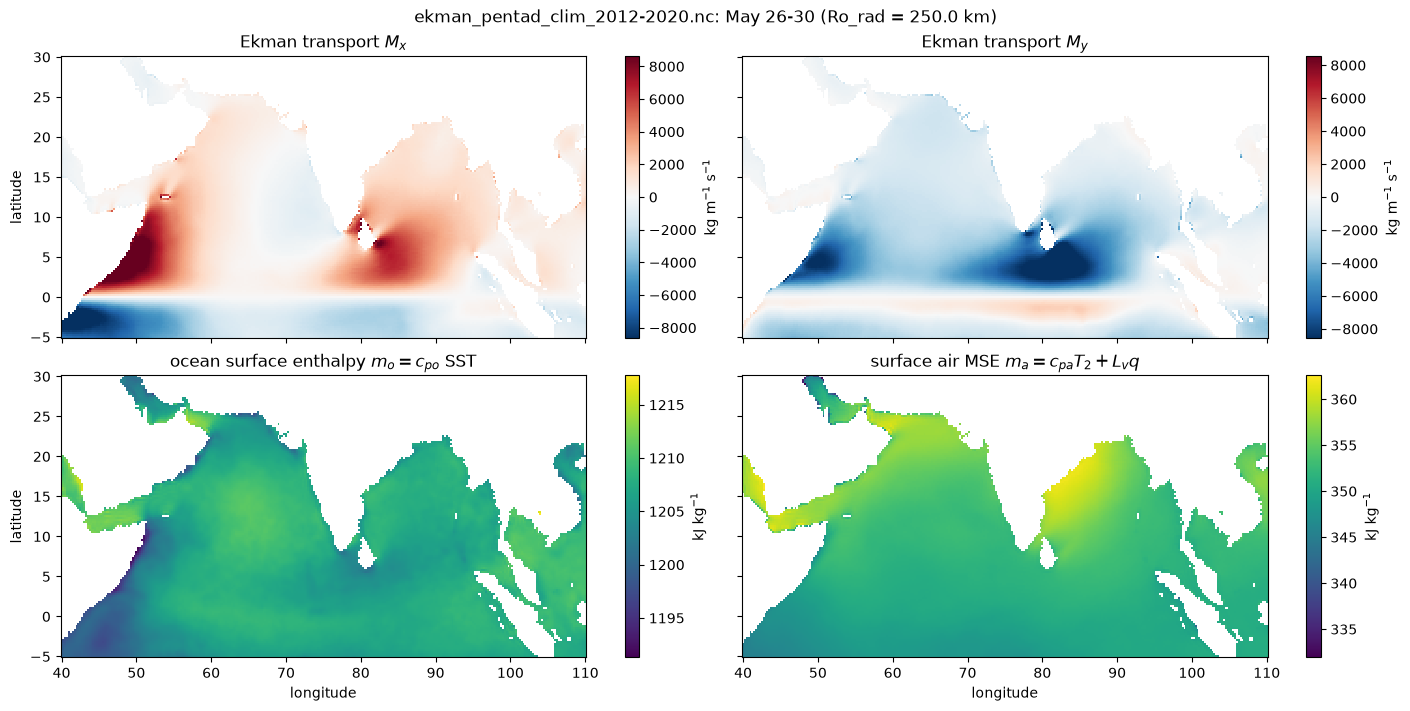

In [13]:
panels1 = [
    panel(f.Mx, raw"Ekman transport $M_x$", raw"kg m$^{-1}$ s$^{-1}$"),
    panel(f.My, raw"Ekman transport $M_y$", raw"kg m$^{-1}$ s$^{-1}$"),
    panel(f.m_o ./ 1e3, raw"ocean surface enthalpy $m_o = c_{po}$ SST", raw"kJ kg$^{-1}$"; cmap="viridis", vmin=nothing, vmax=nothing),
    panel(f.m_a ./ 1e3, raw"surface air MSE $m_a = c_{pa} T_2 + L_v q$", raw"kJ kg$^{-1}$"; cmap="viridis", vmin=nothing, vmax=nothing)]
fig1, axs1 = plot_panels(f.lon, f.lat, panels1; land=f.land, suptitle=figtitle);

In [8]:
# figures display at the end of the cell that makes them; to adjust the axes and show it again:
# axs1[0, 0].set_xlim(50, 100); axs1[0, 0].set_ylim(-5, 25); display(fig1)

## Gradients and Ekman advection
Columns: ocean, atmosphere; gradients per km. The advection is from the saved composites of daily products (`adv_*`); both advection panels share ±`advlim`.

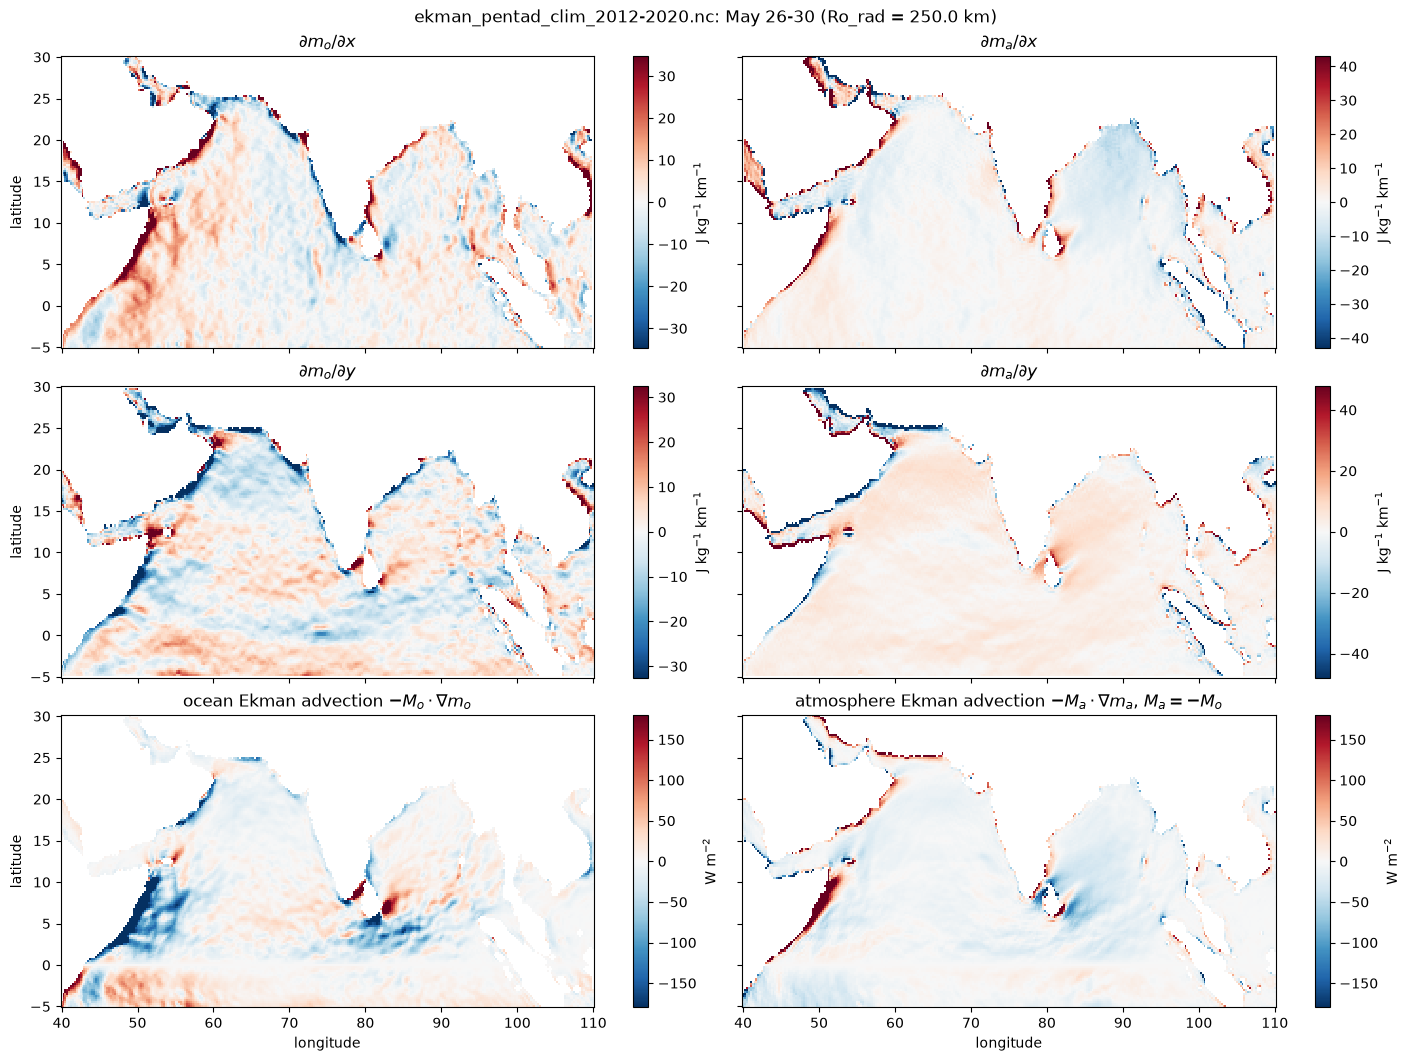

In [9]:
advlim = 180 # W m^-2
panels2 = [
    panel(1e3f.dmodx, raw"$\partial m_o/\partial x$", grad_units), panel(1e3f.dmadx, raw"$\partial m_a/\partial x$", grad_units),
    panel(1e3f.dmody, raw"$\partial m_o/\partial y$", grad_units), panel(1e3f.dmady, raw"$\partial m_a/\partial y$", grad_units),
    panel(f.adv_o, raw"ocean Ekman advection $-M_o \cdot \nabla m_o$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f.adv_a, raw"atmosphere Ekman advection $-M_a \cdot \nabla m_a$, $M_a = -M_o$", flux_units; vmin=-advlim, vmax=advlim)]
fig2, axs2 = plot_panels(f.lon, f.lat, panels2; land=f.land, suptitle=figtitle);

## Ocean and atmosphere Ekman advection and their sum
Columns: ocean, atmosphere, sum. Rows: temperature (SST, $T_2$; mass-weighted, K kg m$^{-2}$ s$^{-1}$), and enthalpy (ocean $m_o$) and moist enthalpy (atmosphere $m_a$), W m$^{-2}$. Each row shares its color limits. Uses `advlim` from the cell above.

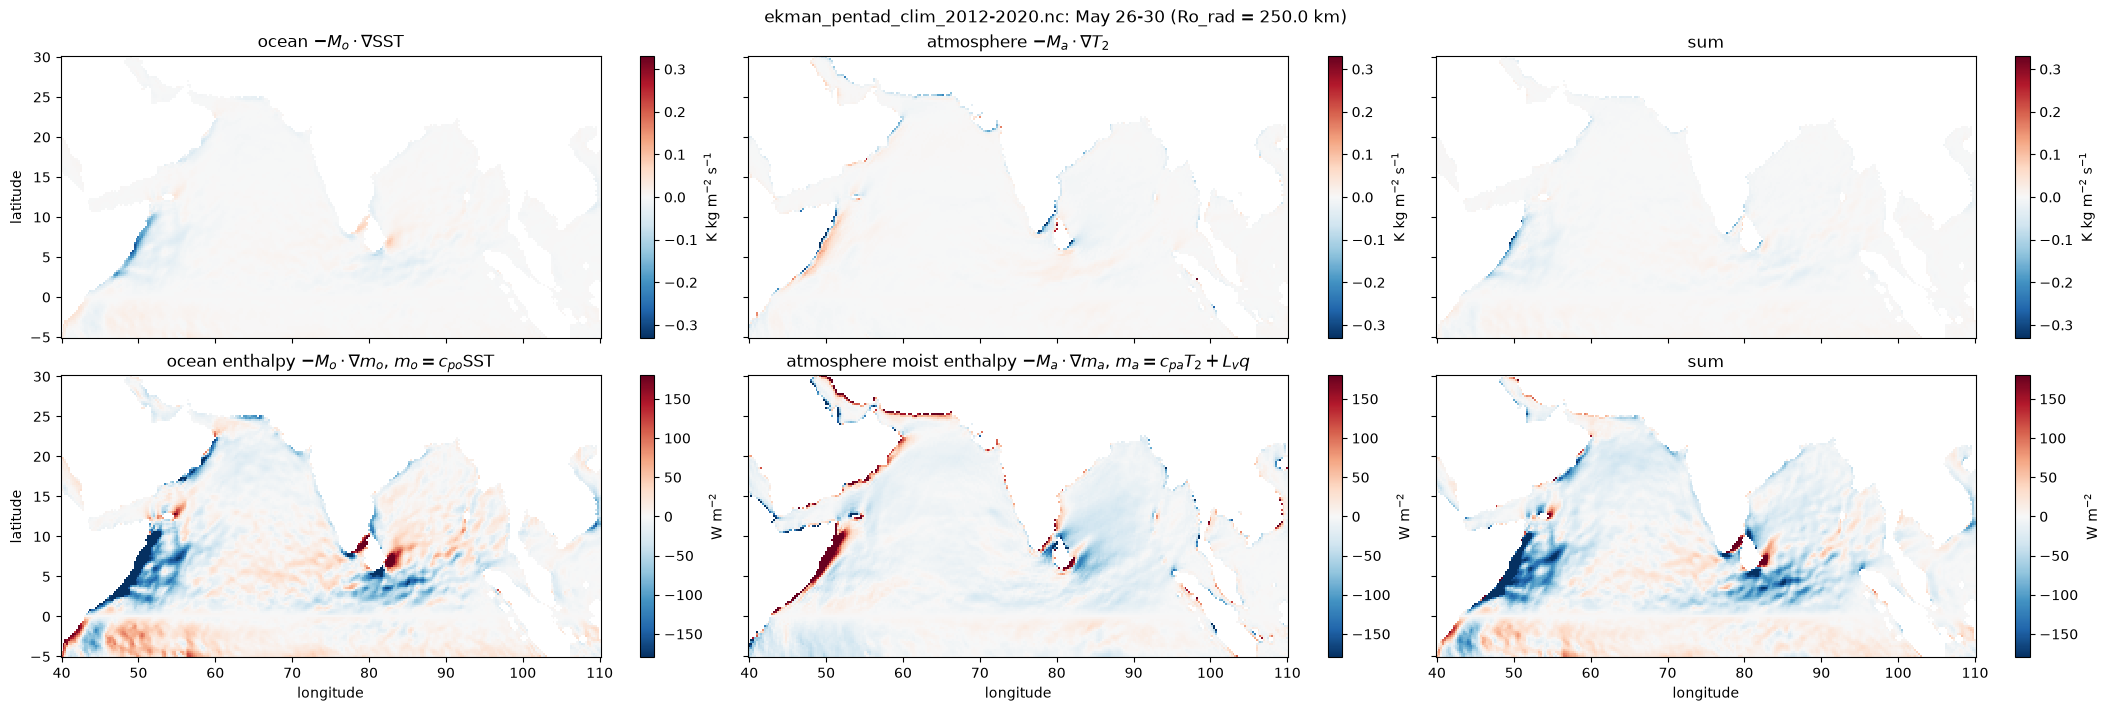

In [10]:
Tlim = maximum(symlim, (f.advT_o, f.advT_a)) # shared by the temperature row
Hlim = advlim                                # W m^-2, shared by the enthalpy row
panels_adv = [
    panel(f.advT_o, raw"ocean $-M_o \cdot \nabla$SST", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.advT_a, raw"atmosphere $-M_a \cdot \nabla T_2$", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.advT_o .+ f.advT_a, "sum", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.adv_o, raw"ocean enthalpy $-M_o \cdot \nabla m_o$, $m_o = c_{po}$SST", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.adv_a, raw"atmosphere moist enthalpy $-M_a \cdot \nabla m_a$, $m_a = c_{pa}T_2 + L_v q$", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.adv_o .+ f.adv_a, "sum", flux_units; vmin=-Hlim, vmax=Hlim)]
fig_adv, axs_adv = plot_panels(f.lon, f.lat, panels_adv; ncols=3, land=f.land, suptitle=figtitle);

## Scalar times transport divergence and flux-form tendency
Columns: ocean, atmosphere. The flux form $-\nabla\cdot(M m)$ is from the saved composites of $s\tau_x$, $s\tau_y$; $m \nabla\cdot M = $ adv $-$ flux. m is measured from 0 K, so $m \nabla\cdot M$ is large and nearly cancels in the flux form.

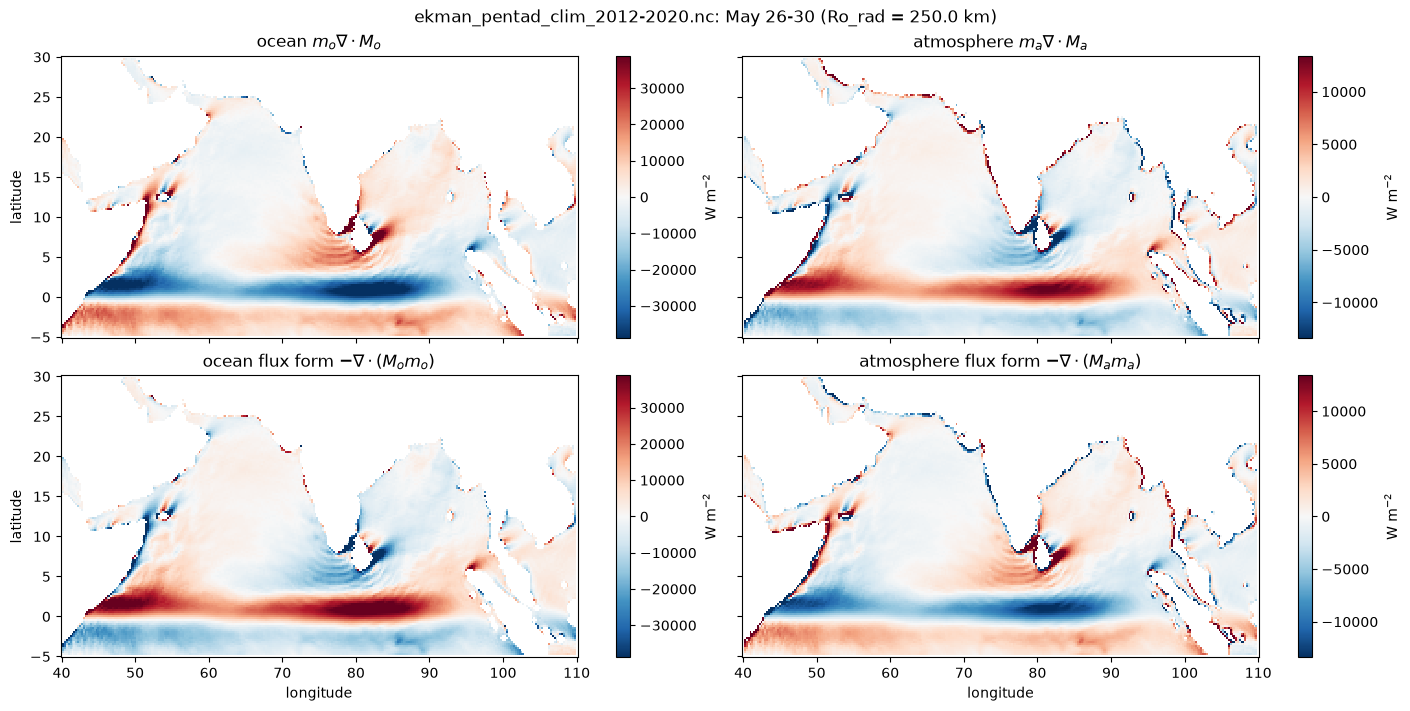

In [11]:
panels3 = [
    panel(f.sdiv_o, raw"ocean $m_o \nabla \cdot M_o$", flux_units),
    panel(f.sdiv_a, raw"atmosphere $m_a \nabla \cdot M_a$", flux_units),
    panel(f.flux_o, raw"ocean flux form $-\nabla \cdot (M_o m_o)$", flux_units),
    panel(f.flux_a, raw"atmosphere flux form $-\nabla \cdot (M_a m_a)$", flux_units)]
fig3, axs3 = plot_panels(f.lon, f.lat, panels3; land=f.land, suptitle=figtitle);

## Save

In [ ]:
# fig1.savefig("ekman_V_ma_mo_pentad$p.png"; dpi=150)
# fig2.savefig("ekman_grad_adv_pentad$p.png"; dpi=150)
# fig_adv.savefig("ekman_adv_sum_pentad$p.png"; dpi=150)
# fig3.savefig("ekman_sdiv_flux_pentad$p.png"; dpi=150)